# Imports

In [6]:
import scipy
import statsmodels
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.stats import kstest

# Carregando e Compreendendo os Dados

Serão considerados dados fictícios para o projeto, gerados a partir do numpy

In [2]:
# Dados de exemplo
np.random.seed(0)
dia = np.arange(1, 101)

In [3]:
# Score de sentimento do cliente (simulado) adicionando ruído, ajustado para variar entre 0 e 10
sentimento = 5 + 3 * np.sin(dia / 10) + np.random.normal(scale = 1.5, size = dia.size)

In [4]:
sentimento = np.clip(sentimento, 0, 10)  # Garantir que os valores estejam entre 0 e 10

In [7]:
# Dataframe
data = pd.DataFrame({'dia': dia, 'sentimento': sentimento})

In [8]:
data.shape

(100, 2)

In [9]:
data.head()

,dia,sentimento
0,1,7.945579
1,2,6.196244
2,3,7.354668
3,4,9.529595
4,5,9.239614


In [10]:
data.describe()

,dia,sentimento
count,100.000000,100.000000
mean,50.500000,5.634943
std,29.011492,2.674644
min,1.000000,0.000000
25%,25.750000,3.757282
50%,50.500000,5.784037
75%,75.250000,7.903660
max,100.000000,10.000000


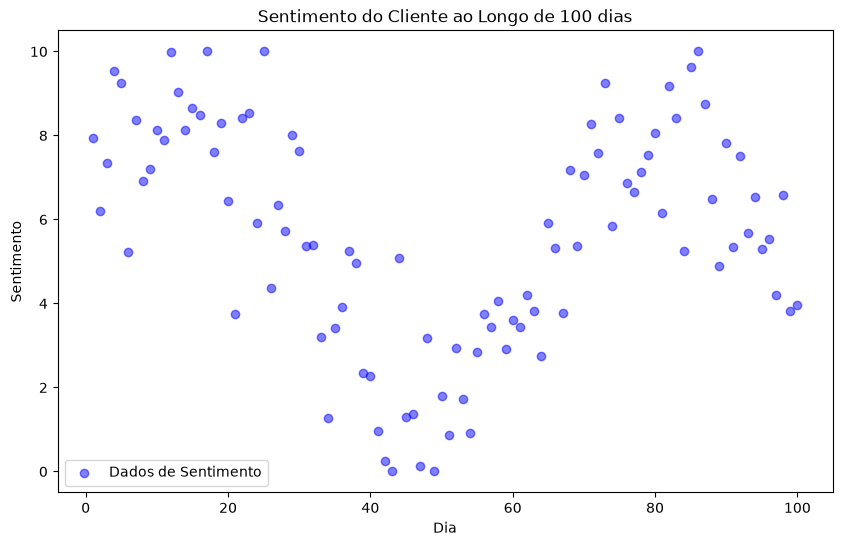

In [13]:
# Plotando os dados
plt.figure(figsize=(10, 6))
plt.scatter(data['dia'],
            data['sentimento'],
            color='blue',
            alpha=0.5,
            label='Dados de Sentimento')
plt.title('Sentimento do Cliente ao Longo de 100 dias')
plt.xlabel('Dia')
plt.ylabel('Sentimento')
plt.legend()
plt.show()

Concluímos que os dados não seguem um padrão linear. Sendo assim, é necessário encontrar o melhor método de regressão para modelar e buscar realizar devidas predições.

# Regressão LOESS (Locally Estimated Sactterplot Smoothing)

In [14]:
# Aplicando a regressão LOESS
frac = 0.1 # fração dos dados usados na janela local
dados_loess = lowess(data['sentimento'], data['dia'], frac=frac)

In [15]:
# Converter o resultado para um DataFrame
loess_df = pd.DataFrame(dados_loess, columns=['dia', 'sentimento_loess'])

In [17]:
# Extraindo valores ajustados
y_fitted = loess_df['sentimento_loess'].values

In [18]:
residuals = data['sentimento'] - y_fitted

In [19]:
residuals

0     0.449593
1    -1.432620
2    -0.366219
3     1.752781
4     1.377636
        ...   
95    0.169855
96   -0.827992
97    1.885634
98   -0.550364
99   -0.068607
Name: sentimento, Length: 100, dtype: float64

O modelo em questão põe uma expectativa de que os resíduos sigam uma normal. Vamos validar com o teste de KS.

# Teste de Kolmogorov-Smirnov

In [21]:
# Padronizar os resíduos e testar contra uma normal padrão
residuals_standardized = (residuals - residuals.mean()) / residuals.std(ddof=0)

ks_stats, p_value = kstest(residuals_standardized, 'norm')

print(f"Estatística KS: {ks_stats:.4f}")
print(f"Valor-p: {p_value:.4f}")

Estatística KS: 0.0581
Valor-p: 0.8688


In [22]:
# Interpretação do resultado
if p_value < 0.05:
    print("Os resíduos não seguem uma distribuição normal (rejeitamos H0).")
else:
    print("Não há evidências suficientes para rejeitar a normalidade dos resíduos (não rejeitamos H0).")

Não há evidências suficientes para rejeitar a normalidade dos resíduos (não rejeitamos H0).


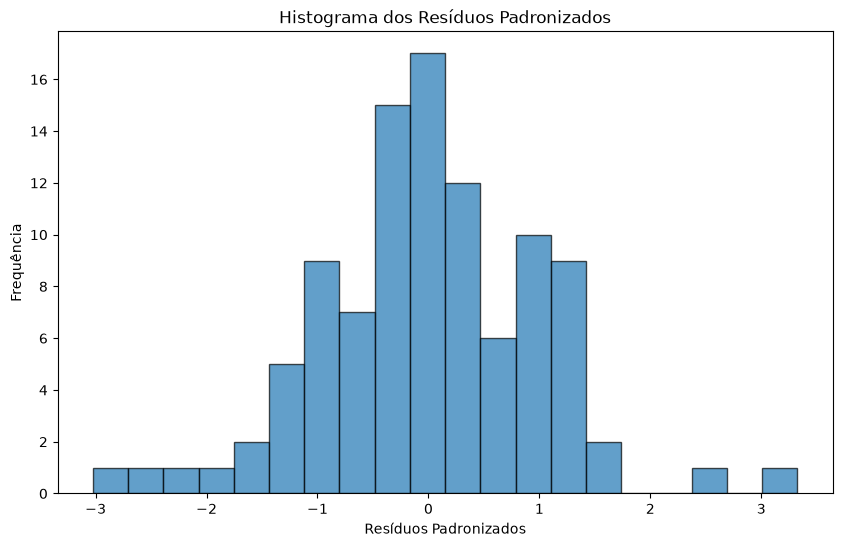

In [23]:
# Visualizando os resíduos padronizados
plt.figure(figsize=(10, 6))
plt.hist(residuals_standardized, bins=20, edgecolor='black', alpha=0.7)
plt.title('Histograma dos Resíduos Padronizados')
plt.xlabel('Resíduos Padronizados')
plt.ylabel('Frequência')
plt.show()

Os resíduos seguem uma distribuição normal.

# Visualizando o Ajuste do Modelo

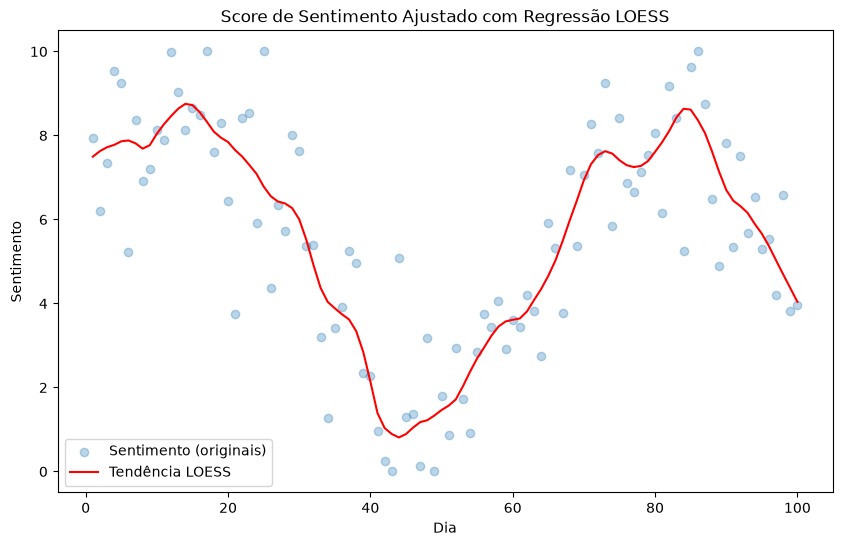

In [24]:
plt.figure(figsize=(10, 6))
plt.scatter(data['dia'], data['sentimento'], alpha=0.3, label='Sentimento (originais)')
plt.plot(loess_df['dia'], loess_df['sentimento_loess'], color='red', label='Tendência LOESS')
plt.xlabel('Dia')
plt.ylabel('Sentimento')
plt.title('Score de Sentimento Ajustado com Regressão LOESS')
plt.legend()
plt.show()